# CXAS: named anatomical landmarks and measurements

CXAS places 132 named anatomical landmarks (about 200 points on a frontal, 100 on a lateral: many landmarks exist per
vertebra or rib) and derives the clinical measurements radiologists take from them: cardiothoracic ratio,
costophrenic angles, Cobb angle, Hoffman-Rigler sign, sternovertebral distance, ...

The example images come from the [NCI Imaging Data Commons](https://portal.imaging.datacommons.cancer.gov/) (CC BY): a PA + lateral pair of one patient from LIDC-IDRI and a portable AP film from COVID-19-NY-SBU. `demo_utils.get_example_images()` downloads them once into `example_data/` (needs `pip install idc-index`); sources and citations are in [`demo_utils.py`](demo_utils.py).

In [1]:
# !pip install cxas idc-index

In [2]:
import warnings; warnings.filterwarnings("ignore")
import transformers; transformers.utils.logging.disable_progress_bar()
import matplotlib.pyplot as plt; plt.rcParams["figure.dpi"] = 72
import torch
from demo_utils import get_example_images, display_image, overlay

DEVICE = "0" if torch.cuda.is_available() else "cpu"     # a GPU number, or "cpu"
paths = get_example_images()                              # downloads ~30 MB from the Imaging Data Commons once
paths

{'frontal_pa': 'example_data/frontal_pa.dcm',
 'lateral': 'example_data/lateral.dcm',
 'frontal_ap_portable': 'example_data/frontal_ap_portable.dcm',
 'frontal_pa_png': 'example_data/png/frontal_pa.png',
 'frontal_pa_jpg': 'example_data/jpg/frontal_pa.jpg',
 'dir': 'example_data'}

In [3]:
import numpy as np
import pydicom
from cxas.landmarks import LandmarkDetector
from cxas.units import physical_spacing

detector = LandmarkDetector(device="cpu" if DEVICE == "cpu" else f"cuda:{DEVICE}")

def load(path):
    """uint8 greyscale image (DICOM window applied) and its pixel spacing."""
    return (display_image(path) * 255).astype(np.uint8), physical_spacing(pydicom.dcmread(path, stop_before_pixels=True))

frontal, frontal_spacing = load(paths["frontal_pa"])
lateral, lateral_spacing = load(paths["lateral"])
lm_frontal = detector.predict(frontal, view="frontal")
lm_lateral = detector.predict(lateral, view="lateral")
print(len(lm_frontal), "frontal and", len(lm_lateral), "lateral landmarks")
lm_frontal[0]

203 frontal and 108 lateral landmarks


{'class': 'vertebrae T1',
 'landmark': 'superior_left',
 'x': 1134.2904052734375,
 'y': 162.60147094726562,
 'confidence': 0.8845844864845276}

Coordinates are in the image's own pixels. Every point has a confidence: structures that are not visible get a low one, and their position means nothing (`cxas_idc` drops points below 0.1 from its DICOM report).

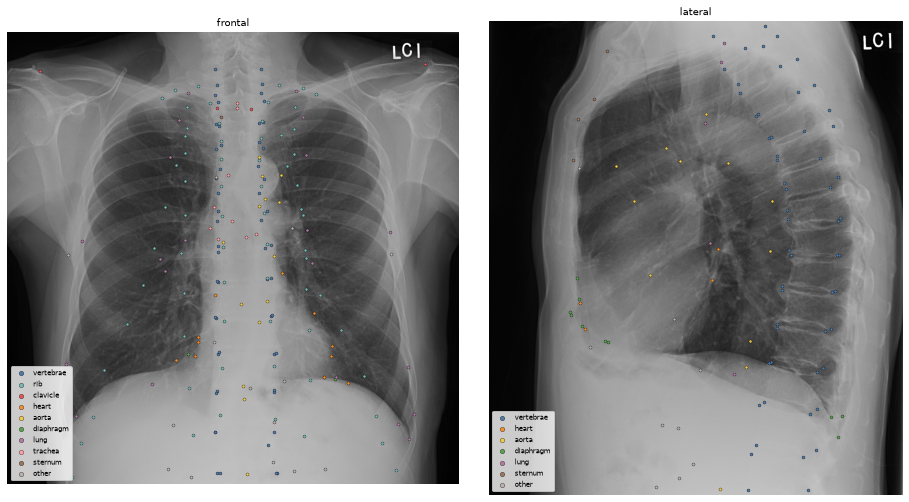

In [4]:
import matplotlib.pyplot as plt
from demo_utils import COLOURS

GROUPS = ["vertebrae", "rib", "clavicle", "heart", "aort", "diaphragm", "lung", "trache", "sternum"]

def group(c):
    return next((g for g in GROUPS if g in c), "other")

def plot_landmarks(ax, image, landmarks, title, min_conf=0.1):
    ax.imshow(image, cmap="gray"); ax.axis("off"); ax.set_title(title, fontsize=10)
    for g in GROUPS + ["other"]:
        pts = [(l["x"], l["y"]) for l in landmarks if l["confidence"] >= min_conf and group(l["class"]) == g]
        if pts:
            x, y = zip(*pts)
            ax.scatter(x, y, s=9, color=COLOURS[(GROUPS + ["other"]).index(g)], edgecolors="black", linewidths=0.3,
                       label={"aort": "aorta", "trache": "trachea"}.get(g, g))
    ax.legend(fontsize=7, loc="lower left", framealpha=0.8, markerscale=1.5)

fig, ax = plt.subplots(1, 2, figsize=(13, 7))
plot_landmarks(ax[0], frontal, lm_frontal, "frontal")
plot_landmarks(ax[1], lateral, lm_lateral, "lateral")
plt.tight_layout()

In [5]:
import pandas as pd

df = pd.DataFrame(lm_frontal)
df[df["class"].str.contains("tracheal bifurcation|hemidiaphragm|heart")].sort_values("confidence", ascending=False).head(10)

,class,landmark,x,y,confidence
200,tracheal bifurcation,right_main_bronchus,907.309631,876.239319,0.957771
202,tracheal bifurcation,subcarinal_limb_right,944.830872,925.777161,0.945943
131,left hemidiaphragm,dome,1464.593506,1552.892944,0.891846
143,heart,left_cardiac_border,1453.280640,1404.390625,0.826962
147,heart,waist_cardiac,1231.358398,1079.436523,0.815693
148,heart,cardiophrenic_left_limb_heart,1449.488525,1448.089111,0.784666
151,heart,cardiophrenic_right_limb_diaphragm,753.205872,1465.260864,0.734489
144,heart,apex,1415.746582,1541.075562,0.715634
145,heart,cardiophrenic_cardiac_left,1417.392456,1541.091431,0.715103
150,heart,cardiophrenic_right_limb_heart,853.532532,1364.691284,0.714411


## Measurements

With a pixel spacing (here from the DICOM header), lengths also come in mm. `CRITERIA` lists the literature thresholds each measurement is compared against.

In [6]:
from cxas.landmarks.measurements import measure, haller_index, CRITERIA

m_frontal = measure(lm_frontal, view="frontal", spacing=frontal_spacing)
m_lateral = measure(lm_lateral, view="lateral", spacing=lateral_spacing)
print("spacing from:", frontal_spacing["source"])
print(f"cardiothoracic ratio  {m_frontal['ctr']:.2f}   (abnormal: {CRITERIA['cardiomegaly']['description']})")
print(f"costophrenic angle    {m_frontal['cp_angle_max']:.0f} deg")
print(f"Cobb angle            {m_frontal['cobb_axis']:.1f} deg")
print(f"thorax width          {m_frontal['thorax_width_mm']:.0f} mm")
print(f"kyphosis              {m_lateral['kyphosis_axis']:.1f} deg")
print(f"sternovertebral dist. {m_lateral['sv_dist_mm']:.0f} mm")

spacing from: ImagerPixelSpacing / (DistanceSourceToDetector / DistanceSourceToPatient)
cardiothoracic ratio  0.39   (abnormal: Cardiothoracic ratio > 0.5)
costophrenic angle    31 deg
Cobb angle            2.8 deg
thorax width          289 mm
kyphosis              36.6 deg
sternovertebral dist. 147 mm


Frontal and lateral of the same patient together give the radiographic Haller index (thorax width / sternovertebral distance; above about 3.25 suggests pectus excavatum):

In [7]:
print(f"Haller index {haller_index(m_frontal, m_lateral):.2f}")

Haller index 1.97


In [8]:
pd.DataFrame([{"name": k, **v} for k, v in CRITERIA.items()])[["name", "view", "measurement", "description", "source"]]

,name,view,measurement,description,source
0,cardiomegaly,frontal,ctr,Cardiothoracic ratio > 0.5,danzer1919
1,cardiomegaly_lateral,lateral,hoffman_rigler,Hoffman-Rigler sign: posterior heart border be...,hoffman1965
2,pleural_effusion,frontal,cp_angle_max,Blunted lateral costophrenic angle (degrees),blackmore1996
3,pleural_effusion_lateral,lateral,post_sulcus_depth,Posterior costophrenic sulcus filled,collins1972
4,low_lung_volumes,frontal,rib_level,Right dome above the 10th posterior rib,eur16260
5,hyperinflation,frontal,rib_level,Low diaphragm (posterior rib level of the righ...,eur16260
6,hyperinflation_flat_dome,frontal,dome_height,Flattened hemidiaphragm dome,pratt1987
7,hyperinflation_lateral,lateral,dome_height_lat,Flattened diaphragm on the lateral,pratt1987
8,hyperinflation_retrosternal,lateral,retrosternal,Enlarged retrosternal clear space,pratt1987
9,hyperinflation_ap_depth,lateral,ap_depth,Antero-posterior chest depth (barrel chest),


Research measurements: thresholds come from the literature and were tested against radiology reports, not validated for diagnosis. `cxas_idc` (see [`IDC_DicomInDicomOut.ipynb`](IDC_DicomInDicomOut.ipynb)) computes all of them and writes them into a DICOM Structured Report.